In [1]:
# unzip files
!unzip -q hw6.zip
%cd hw6

# # after restarting the kernel, make sure the files are still available
# %cd /content/hw5
!ls


/content/hw6
base_classification.py	hw6.md	     requirements.txt
classification.py	overfit.png  rkhandpur_hw6_scrap_local.ipynb


In [2]:
import torch

In [3]:
# confirming gpu access
print(torch.cuda.is_available(), torch.cuda.get_device_name(0))

True NVIDIA RTX PRO 6000 Blackwell Server Edition


In [4]:
# # install requirements
# !pip install -q -r requirements.txt # this errored so tried directly below
# !pip install -q datasets==2.17.1 evaluate==0.4.1 matplotlib==3.8.3 openai==1.12.0 regex==2023.12.25 transformers==4.38.1 scikit-learn
!pip install -q -U "numpy>=2" "transformers>=4.46,<5" "datasets>=3" "evaluate>=0.4.3" "matplotlib>=3.9" scikit-learn
# # %cd /content/hw6        # your folder
import numpy, torch, transformers, datasets, evaluate
print(numpy.__version__, torch.__version__, transformers.__version__, datasets.__version__)
print("CUDA:", torch.cuda.is_available())


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.4 which is incompatible.
2.4.6 2.14.1+cu130 4.57.6 5.0.1
CUDA: True


In [5]:
# training on all the data and 30 epochs
!python base_classification.py --device cuda --model distilbert-base-uncased --num_epochs 30 --batch_size 32 --lr 5e-5 2>&1 | tee train_full.log

I0000 00:00:1794191482.594520    5888 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794191483.679413    5888 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794191483.679676    5888 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Specified arguments: Namespace(small_subset=False, num_epochs=30, lr=5e-05, batch_size=32, device='cuda', model='distilbert-base-uncased')
Loading the dataset ...
Generating validation split: 100%|██████████| 3270/3270 [00:00<00:00, 683342.84 examples/s]
Some weights of DistilBertForSequenceClassification were no

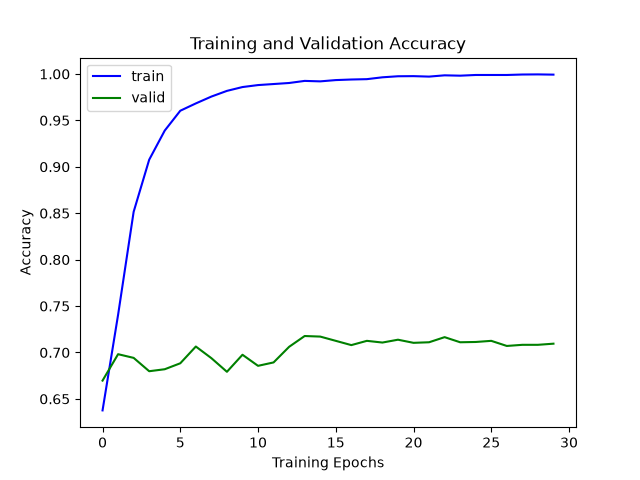

In [6]:
from IPython.display import Image
Image("base_full.png")

In [7]:
# Hyperparameter Grid-Search
%%writefile hp_search.py
import os, itertools, csv
os.environ.setdefault("USE_TF", "0")          # don't let transformers load TensorFlow

import torch
from transformers import set_seed
from base_classification import pre_process, train, evaluate_model

LRS     = [1e-4, 5e-4, 1e-3]
EPOCHS  = [7, 9]
SEED    = 42
MODEL   = "distilbert-base-uncased"
DEVICE  = "cuda"
BATCH   = 32

results = []
best = {"dev_acc": -1.0}

for lr, num_epochs in itertools.product(LRS, EPOCHS):
    print(f"\n{'='*20} lr={lr}, epochs={num_epochs} {'='*20}")

    # same seed for every run -> same data shuffle/split and same classifier-head init
    set_seed(SEED)
    model, train_dl, dev_dl, test_dl = pre_process(MODEL, BATCH, DEVICE, small_subset=False)

    train(model, num_epochs, train_dl, dev_dl, test_dl, DEVICE, lr)
    os.rename("base_full.png", f"base_lr{lr}_ep{num_epochs}.png")   # keep each run's plot

    dev_acc = evaluate_model(model, dev_dl, DEVICE)["accuracy"]
    results.append({"lr": lr, "epochs": num_epochs, "dev_acc": dev_acc})
    print(f">>> lr={lr}, epochs={num_epochs}: DEV accuracy = {dev_acc:.4f}")

    if dev_acc > best["dev_acc"]:
        # keep the best model (parked on CPU to free GPU memory) and its test loader
        if "model" in best:
            del best["model"]
        best = {"lr": lr, "epochs": num_epochs, "dev_acc": dev_acc,
                "model": model.to("cpu"), "test_dl": test_dl}
    else:
        del model
    torch.cuda.empty_cache()

# ---- summary ----
print("\n===== Grid search results (selected by DEV accuracy) =====")
print(f"{'lr':>8} {'epochs':>7} {'dev_acc':>8}")
for r in results:
    print(f"{r['lr']:>8} {r['epochs']:>7} {r['dev_acc']:>8.4f}")

with open("hp_results.csv", "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=["lr", "epochs", "dev_acc"])
    w.writeheader(); w.writerows(results)

# ---- evaluate ONLY the selected model on test ----
best_model = best["model"].to(DEVICE)
test_acc = evaluate_model(best_model, best["test_dl"], DEVICE)["accuracy"]
print(f"\nBEST hyperparameters: lr={best['lr']}, epochs={best['epochs']}")
print(f"BEST DEV accuracy:  {best['dev_acc']:.4f}")
print(f"TEST accuracy:      {test_acc:.4f}")

Writing hp_search.py


In [8]:
!python hp_search.py 2>&1 | tee hp_search.log

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.

==================== lr=0.0001, epochs=7 ====================
Loading the dataset ...
Slicing the data...
Size of the loaded dataset:
 - train: 8000
 - dev: 3270
 - test: 1427
Loading the tokenizer...
Loding the data into DS...
 >>>>>>>> Initializing the data loaders ... 
Loading the model ...
Moving model to device ...cuda
 >>>>>>>>  Initializing optimizer
Epoch 1 training:
250it [00:09, 26.93it/s]
 ===> Epoch 1
 - Average training metrics: accuracy={'accuracy': 0.63825}
 - Average validation metrics: accuracy={'accuracy': 0.6513761467889908}
Epoch 2 training:
250it [00:08, 28.37it/s]
 ===> Epoch 2
 - Average training metrics: accuracy={

In [11]:
import pandas as pd
pd.read_csv("hp_results.csv").sort_values("dev_acc", ascending=False)

,lr,epochs,dev_acc
0,0.0001,7,0.705810
1,0.0001,9,0.682569
2,0.0005,7,0.621713
3,0.0005,9,0.621713
4,0.0010,7,0.621713
5,0.0010,9,0.621713


# running the same grid-search on BERT models.

In [12]:
import os, gc, itertools
os.environ["USE_TF"] = "0"   # skip TensorFlow (set before transformers is imported)

import importlib, torch, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from transformers import set_seed
import base_classification as bc
importlib.reload(bc)          # picks up any edits to base_classification.py

LRS, EPOCHS = [1e-4, 5e-4, 1e-3], [7, 9]
SEED, DEVICE = 42, "cuda"
BATCH_SIZES = [32, 16, 8]     # fall back to smaller on GPU OOM

def free_gpu():
    gc.collect(); torch.cuda.empty_cache()

def run_one(model_name, lr, num_epochs, batch_size):
    set_seed(SEED)            # same split + head init every run
    model, train_dl, dev_dl, test_dl = bc.pre_process(model_name, batch_size, DEVICE, small_subset=False)
    bc.train(model, num_epochs, train_dl, dev_dl, test_dl, DEVICE, lr)
    os.rename("base_full.png", f"{model_name.replace('/','_')}_lr{lr}_ep{num_epochs}.png")
    dev_acc = bc.evaluate_model(model, dev_dl, DEVICE)["accuracy"]
    return model, dev_acc, test_dl

def grid_search(model_name):
    print(f"\n{'#'*20} MODEL: {model_name} {'#'*20}")
    batch_size, best, rows = None, {"dev_acc": -1.0}, []
    for lr, ne in itertools.product(LRS, EPOCHS):
        result = None
        for bs in ([batch_size] if batch_size else BATCH_SIZES):
            oom = False
            try:
                print(f"\n=== {model_name}: lr={lr}, epochs={ne}, batch_size={bs} ===")
                result = run_one(model_name, lr, ne, bs)
                batch_size = bs
                break
            except torch.cuda.OutOfMemoryError:
                oom = True
            if oom:
                print(f"!!! OOM at batch_size={bs}"); free_gpu()
        if result is None:
            print(f"!!! {model_name} doesn't fit -> reporting 0")
            return dict(model=model_name, best_lr=np.nan, best_epochs=np.nan,
                        batch_size=np.nan, dev_acc=0.0, test_acc=0.0), rows

        model, dev_acc, test_dl = result
        rows.append(dict(model=model_name, lr=lr, epochs=ne, batch_size=batch_size, dev_acc=dev_acc))
        print(f">>> DEV = {dev_acc:.4f}")
        if dev_acc > best["dev_acc"]:
            best.pop("model", None)
            best = dict(lr=lr, epochs=ne, dev_acc=dev_acc, model=model.to("cpu"), test_dl=test_dl)
        else:
            del model
        free_gpu()

    # test only the dev-selected model
    test_acc = bc.evaluate_model(best["model"].to(DEVICE), best["test_dl"], DEVICE)["accuracy"]
    summary = dict(model=model_name, best_lr=best["lr"], best_epochs=best["epochs"],
                   batch_size=batch_size, dev_acc=best["dev_acc"], test_acc=test_acc)
    print(f"\n*** BEST {summary}")
    del best; free_gpu()
    return summary, rows


#################### MODEL: bert-base-uncased ####################

=== bert-base-uncased: lr=0.0001, epochs=7, batch_size=32 ===
Loading the dataset ...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Slicing the data...
Size of the loaded dataset:
 - train: 8000
 - dev: 3270
 - test: 1427
Loading the tokenizer...


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

... (224 outputs left out)

250it [00:15, 16.15it/s]


 ===> Epoch 9
 - Average training metrics: accuracy={'accuracy': 0.623125}
 - Average validation metrics: accuracy={'accuracy': 0.6217125382262997}
>>> DEV = 0.6217

*** BEST {'model': 'roberta-base', 'best_lr': 0.0001, 'best_epochs': 7, 'batch_size': 32, 'dev_acc': 0.6217125382262997, 'test_acc': 0.6229852838121934}


,model,best_lr,best_epochs,batch_size,dev_acc,test_acc
0,bert-base-uncased,0.0001,7,32,0.709480,0.695165
1,roberta-base,0.0001,7,32,0.621713,0.622985


,model,lr,epochs,batch_size,dev_acc
0,bert-base-uncased,0.0001,7,32,0.709480
1,bert-base-uncased,0.0001,9,32,0.696942
2,bert-base-uncased,0.0005,7,32,0.621713
3,bert-base-uncased,0.0005,9,32,0.621713
4,bert-base-uncased,0.0010,7,32,0.621713
5,bert-base-uncased,0.0010,9,32,0.621713
6,roberta-base,0.0001,7,32,0.621713
7,roberta-base,0.0001,9,32,0.621713
8,roberta-base,0.0005,7,32,0.621713
9,roberta-base,0.0005,9,32,0.621713


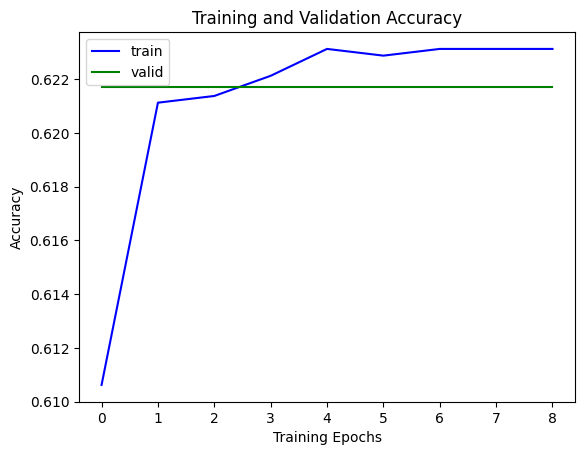

In [13]:
MODELS = ["bert-base-uncased", "roberta-base"]

summaries, all_rows = [], []
for m in MODELS:
    s, rows = grid_search(m)
    summaries.append(s); all_rows.extend(rows)

results = pd.DataFrame(summaries)
grid    = pd.DataFrame(all_rows)
results.to_csv("model_results.csv", index=False)
grid.to_csv("model_grid_all.csv", index=False)
display(results)
display(grid.sort_values(["model", "dev_acc"], ascending=[True, False]))

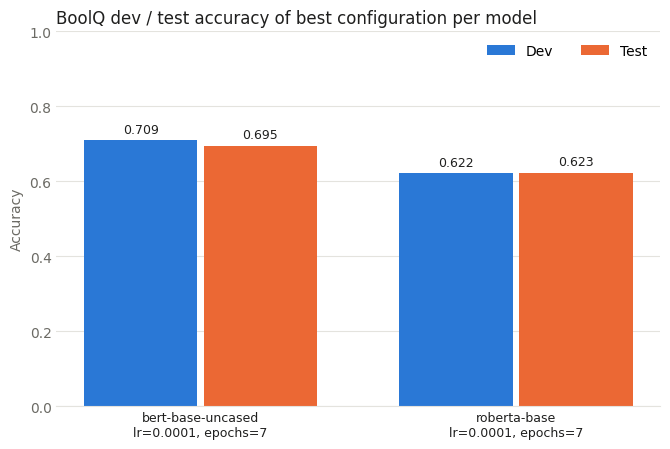

In [14]:
df = results
x, w, gap = np.arange(len(df)), 0.36, 0.01
INK, MUTED, GRID = "#1f1f1e", "#6b6a64", "#e4e3de"

fig, ax = plt.subplots(figsize=(1.9 * len(df) + 3, 4.6))
b1 = ax.bar(x - w/2 - gap, df["dev_acc"],  w, color="#2a78d6", label="Dev")
b2 = ax.bar(x + w/2 + gap, df["test_acc"], w, color="#eb6834", label="Test")
for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h:.3f}", (bar.get_x() + bar.get_width()/2, h), xytext=(0, 3),
                    textcoords="offset points", ha="center", va="bottom", fontsize=9, color=INK)

labels = [f"{r.model}\n(did not fit: 0)" if r.dev_acc == 0 and r.test_acc == 0
          else f"{r.model}\nlr={r.best_lr:g}, epochs={int(r.best_epochs)}" for r in df.itertuples()]
ax.set_xticks(x, labels, fontsize=9, color=INK)
ax.set_ylim(0, 1.0); ax.set_ylabel("Accuracy", color=MUTED)
ax.set_title("BoolQ dev / test accuracy of best configuration per model", loc="left", color=INK)
ax.yaxis.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True)
for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.tick_params(axis="y", colors=MUTED, length=0); ax.tick_params(axis="x", length=0)
ax.legend(frameon=False, loc="upper right", ncol=2)
plt.tight_layout(); plt.savefig("model_comparison.png", dpi=150); plt.show()